In [19]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import f1_score,roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

import lightgbm as lgb
from catboost import CatBoostClassifier

from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks,savgol_filter
from scipy.integrate import trapezoid
from scipy.optimize import curve_fit

from imblearn.over_sampling import SMOTE
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_SPLITS = 5

## 1. Carga de logs

In [2]:
train_log = pd.read_csv("/kaggle/input/mallorn-dataset/train_log.csv")
test_log = pd.read_csv("/kaggle/input/mallorn-dataset/test_log.csv")

## 2. Cargar light curves

In [3]:
def load_lightcurve(split, object_id, is_train=True):
    base = "train" if is_train else "test"
    path = f"/kaggle/input/mallorn-dataset/{split}/{base}_full_lightcurves.csv"
    df = pd.read_csv(path)
    return df[df["object_id"] == object_id]

## 3. Features

In [4]:
def bazin(t, A, t0, tau_rise, tau_fall, B):
    return A * np.exp(-(t - t0) / tau_fall) / (1 + np.exp(-(t - t0) / tau_rise)) + B

def fit_powerlaw(time, flux):
    # placeholder simplificado
    # Ajuste real: log-log regression o similar
    if len(time) < 2:
        return 0
    coeffs = np.polyfit(np.log(time - time[0] + 1e-3), np.log(np.abs(flux) + 1e-3), 1)
    return coeffs[0]

def fit_bazin_and_chi2(time, flux, flux_err):
    # Normalización temporal para estabilidad numérica
    t = time - time.min()

    # Initial guesses (CRÍTICO)
    A0 = np.max(flux) - np.median(flux)
    t00 = t[np.argmax(flux)]
    tau_rise0 = max(1.0, 0.1 * (t.max() - t.min()))
    tau_fall0 = max(1.0, 0.3 * (t.max() - t.min()))
    B0 = np.median(flux)

    p0 = [A0, t00, tau_rise0, tau_fall0, B0]

    bounds = (
        [0, 0, 0.1, 0.1, -np.inf],    # lower
        [np.inf, t.max(), 1000, 5000, np.inf]  # upper
    )

    try:
        popt, _ = curve_fit(
            bazin,
            t,
            flux,
            p0=p0,
            sigma=flux_err + 1e-3,
            absolute_sigma=True,
            bounds=bounds,
            maxfev=10000
        )

        model_flux = bazin(t, *popt)
        chi2 = np.mean(((flux - model_flux) / (flux_err + 1e-3)) ** 2)

        return {
            "bazin_A": popt[0],
            "bazin_t0": popt[1],
            "bazin_tau_rise": popt[2],
            "bazin_tau_fall": popt[3],
            "bazin_B": popt[4],
            "bazin_chi2": chi2
        }

    except Exception:
        # Fallo de ajuste = AGN-like
        return {
            "bazin_A": 0,
            "bazin_t0": 0,
            "bazin_tau_rise": 0,
            "bazin_tau_fall": 0,
            "bazin_B": 0,
            "bazin_chi2": 1e6
        }


def extract_features_tde_full(lc):
    """Extrae features inspiradas en la estrategia del ganador: estadísticas, FER, Bazin (simplificado), físicas"""
    features = {}
    if len(lc) < 5:
        return features

    lc = lc.sort_values("Time (MJD)")
    flux = lc["Flux"].values
    time = lc["Time (MJD)"].values
    ferr = lc["Flux_err"].values

    # Estadísticas básicas
    features["flux_mean"] = flux.mean()
    features["flux_std"] = flux.std()
    features["flux_max"] = flux.max()
    features["flux_min"] = flux.min()
    features["amplitude"] = flux.max() - flux.min()
    features["flux_skew"] = skew(flux)
    features["flux_kurt"] = kurtosis(flux)

    # Cuantiles
    features["q05"] = np.quantile(flux, 0.05)
    features["q25"] = np.quantile(flux, 0.25)
    features["q75"] = np.quantile(flux, 0.75)
    features["q95"] = np.quantile(flux, 0.95)
    features["iqr"] = features["q75"] - features["q25"]

    # Temporal
    features["duration"] = time.max() - time.min()
    imax = np.argmax(flux)
    features["t_rise"] = time[imax] - time[0]
    features["t_decay"] = time[-1] - time[imax]
    features["asymmetry"] = features["t_rise"] / (features["t_decay"] + 1e-6)

    # Pendientes
    features["slope_rise"] = (flux[imax] - flux[0]) / (time[imax] - time[0] + 1e-6) if imax>1 else 0
    features["slope_decay"] = (flux[-1] - flux[imax]) / (time[-1] - time[imax] + 1e-6) if imax<len(flux)-2 else 0

    # Smoothness
    features["diff_std"] = np.std(np.diff(flux))
    features["diff_mean"] = np.mean(np.abs(np.diff(flux)))

    # Flux/Error Ratio
    fer = np.abs(flux) / (ferr + 1e-6)
    features["fer_mean"] = fer.mean()
    features["fer_std"] = fer.std()
    features["fer_max"] = fer.max()
    features["fer_min"] = fer.min()
    
    # SNR
    snr = flux / (ferr + 1e-6)
    features["snr_mean"] = snr.mean()
    features["snr_max"] = snr.max()
    features["snr_ratio"] = features["snr_max"] / (features["snr_mean"] + 1e-6)

    # Fluencia
    features["fluence"] = trapezoid(flux, time)

    # Powerlaw slope
    features["powerlaw_slope"] = fit_powerlaw(time, flux)

    # Picos
    peaks, _ = find_peaks(flux, prominence=1)
    features["n_peaks"] = len(peaks)

    # Features por filtro
    for f in ["u","g","r","i","z","y"]:
        df_f = lc[lc["Filter"]==f]
        features[f"{f}_mean"] = df_f["Flux"].mean() if len(df_f)>0 else 0
        features[f"{f}_max"] = df_f["Flux"].max() if len(df_f)>0 else 0
        features[f"{f}_n"] = len(df_f)

    # Colores
    features["g_r"] = features["g_mean"] - features["r_mean"]
    features["r_i"] = features["r_mean"] - features["i_mean"]
    features["i_z"] = features["i_mean"] - features["z_mean"]

    # Delta color
    color_times = np.linspace(time.min(), time.max(), 5)
    delta_colors = []
    for t in range(1,len(color_times)):
        mask_prev = (time>=color_times[t-1]) & (time<color_times[t])
        mask_curr = (time>=color_times[t]) & (time<color_times[t]+1)
        if np.any(mask_prev) and np.any(mask_curr):
            g_prev = lc[mask_prev & (lc["Filter"]=="g")]["Flux"].mean()
            r_prev = lc[mask_prev & (lc["Filter"]=="r")]["Flux"].mean()
            g_curr = lc[mask_curr & (lc["Filter"]=="g")]["Flux"].mean()
            r_curr = lc[mask_curr & (lc["Filter"]=="r")]["Flux"].mean()
            delta_colors.append((g_curr - r_curr) - (g_prev - r_prev))
    features["delta_color_mean"] = np.mean(delta_colors) if len(delta_colors)>0 else 0

    # Placeholder para Bazin fit (real sería ajuste no lineal)
    features["bazin_global_chi2"] = features["flux_std"] / (features["flux_mean"]+1e-6)  # proxy simple

    # Physics-inspired (simplificado)
    features["rise_fall_asymmetry"] = features["t_rise"] / (features["t_decay"]+1e-6)
    features["flux_concentration"] = features["amplitude"] / (features["flux_max"]+1e-6)

    # BAZIN FEATURES
    for f in ["g", "r", "i"]:
        df_f = lc[lc["Filter"] == f]
        if len(df_f) >= 5:
            bf = fit_bazin_and_chi2(
                df_f["Time (MJD)"].values,
                df_f["Flux"].values,
                df_f["Flux_err"].values
            )
            for k, v in bf.items():
                features[f"{f}_{k}"] = v
        else:
            for k in ["A","t0","tau_rise","tau_fall","B","chi2"]:
                features[f"{f}_bazin_{k}"] = 1e6 if k=="chi2" else 0

    return features

## 4. Construir dataset

In [5]:
# ==============================
# Crear dataset de features
# ==============================

def create_feature_matrix(df, is_train=True):
    X_list = []
    y_list = []

    for idx, row in df.iterrows():
        lc = load_lightcurve(row["split"], row["object_id"], is_train=is_train)
        feats = extract_features_tde_full(lc)
        if is_train:
            X_list.append(feats)
            y_list.append(row["target"])
        else:
            X_list.append(feats)

    X = pd.DataFrame(X_list).fillna(0)
    if is_train:
        y = np.array(y_list)
        return X, y
    else:
        return X

In [6]:
# ==============================
# 1️⃣ Crear matrices de features
# ==============================
X_train, y = create_feature_matrix(train_log, is_train=True)
X_test = create_feature_matrix(test_log, is_train=False)

unique, counts = np.unique(y, return_counts=True)
print(unique)
print(counts)

# ==============================
# 2️⃣ Escalar features
# ==============================
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

[0 1]
[2895  148]


## **** Visualización light curves TDE y AGN vs Bazin fit

In [7]:
import matplotlib.pyplot as plt

def bazin(t, A, t0, tau_rise, tau_fall, B):
    return A * np.exp(-(t - t0) / tau_fall) / (1 + np.exp(-(t - t0) / tau_rise)) + B


def fit_bazin_curve(time, flux):
    # valores iniciales razonables
    p0 = [
        np.max(flux) - np.min(flux),  # A
        time[np.argmax(flux)],        # t0
        10.0,                          # tau_rise
        30.0,                          # tau_fall
        np.median(flux)               # B
    ]

    bounds = (
        [0, time.min(), 0.1, 0.1, -np.inf],
        [np.inf, time.max(), 200, 500, np.inf]
    )

    try:
        popt, _ = curve_fit(
            bazin, time, flux,
            p0=p0,
            bounds=bounds,
            maxfev=10000
        )
        return popt
    except RuntimeError:
        return None


def plot_lc_with_bazin(lc, title="Light curve + Bazin"):
    if len(lc) < 5:
        print("Light curve too short")
        return

    lc = lc.sort_values("Time (MJD)")
    time = lc["Time (MJD)"].values
    flux = lc["Flux"].values
    ferr = lc["Flux_err"].values

    plt.figure(figsize=(10, 5))

    # --- Plot puntos por filtro ---
    for f in FILTER_COLORS.keys():
        df_f = lc[lc["Filter"] == f]
        if len(df_f) == 0:
            continue
    
        plt.errorbar(
            df_f["Time (MJD)"],
            df_f["Flux"],
            yerr=df_f["Flux_err"],
            fmt="o",
            ms=4,
            alpha=0.7,
            color=FILTER_COLORS[f],
            label=f"Filter {f}"
        )

    # --- Ajuste Bazin global ---
    try:
        t_fit = np.linspace(time.min(), time.max(), 300)
        popt = fit_bazin_curve(time, flux)
    
        if popt is not None:
            flux_fit = bazin(t_fit, *popt)
            plt.plot(t_fit, flux_fit, "k-", lw=2, label="Bazin fit")
    except Exception as e:
        print("Bazin fit failed:", e)

    plt.xlabel("Time (MJD)")
    plt.ylabel("Flux")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [31]:
lc_tde

,object_id,Time (MJD),Flux,Flux_err,Filter
16447,mithril_suil_cugu,63317.8677,1.429360,1.477216,y
16448,mithril_suil_cugu,63628.1491,0.040413,0.069179,g
16449,mithril_suil_cugu,63322.1181,0.294682,0.219964,r
16450,mithril_suil_cugu,63322.1181,-0.186058,0.376614,i
16451,mithril_suil_cugu,63324.2433,0.056664,0.151692,g
...,...,...,...,...,...
16617,mithril_suil_cugu,62907.7012,-1.735846,1.403472,y
16618,mithril_suil_cugu,62909.8264,0.561291,0.289878,r
16619,mithril_suil_cugu,62920.4525,0.958838,0.298789,z
16620,mithril_suil_cugu,62899.2003,-0.806919,0.489453,z


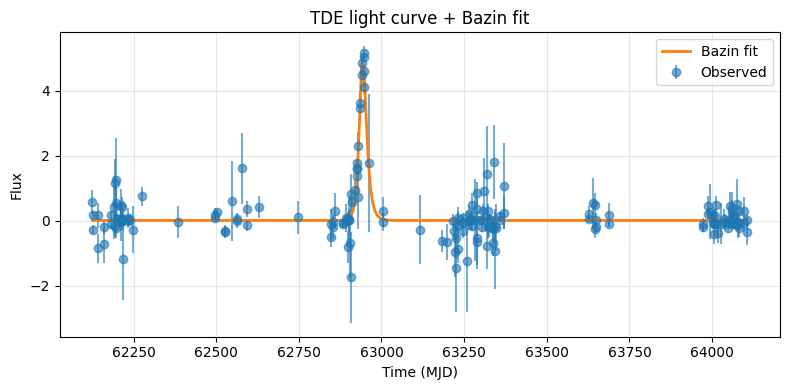

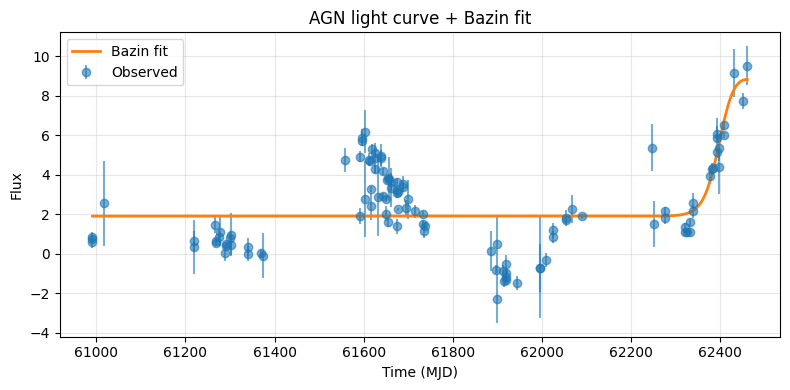

In [26]:
# Ejemplo: elegir un objeto TDE y uno AGN
tde_id = train_log[train_log["SpecType"] == "TDE"].iloc[5]["object_id"]
agn_id = train_log[train_log["SpecType"] == "AGN"].iloc[5]["object_id"]

lc_tde = load_lightcurve("split_01", tde_id, is_train=True)
lc_agn = load_lightcurve("split_01", agn_id, is_train=True)

plot_lc_with_bazin(lc_tde, "TDE light curve + Bazin fit")
plot_lc_with_bazin(lc_agn, "AGN light curve + Bazin fit")

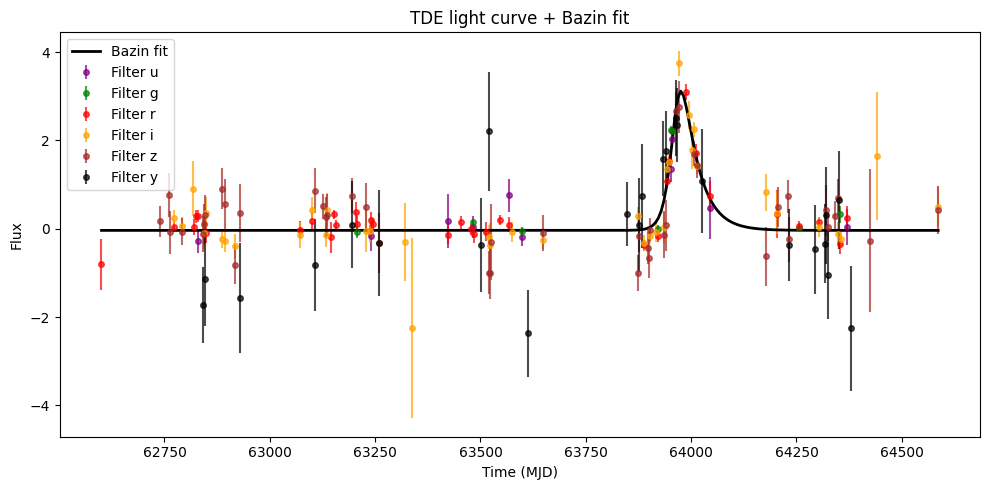

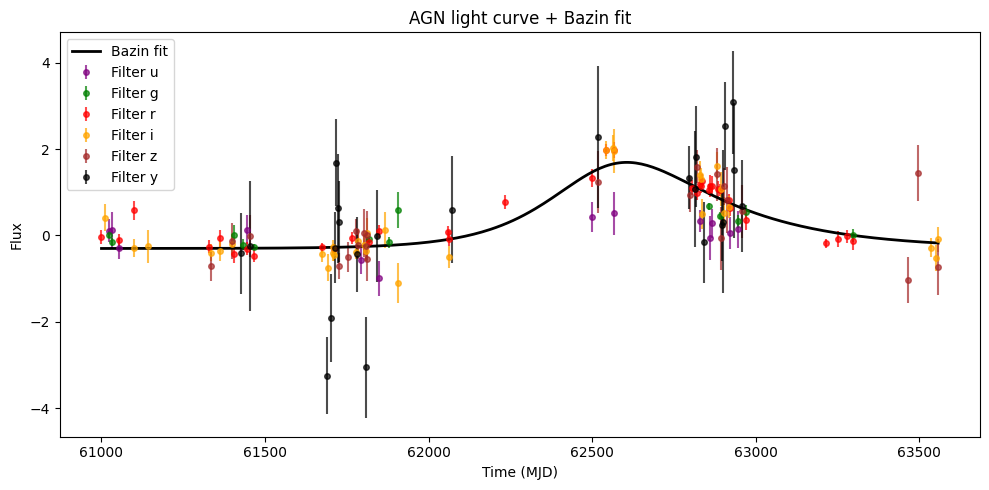

In [9]:
# Ejemplo: elegir un objeto TDE y uno AGN
FILTER_COLORS = {
    "u": "purple",
    "g": "green",
    "r": "red",
    "i": "orange",
    "z": "brown",
    "y": "black"
}

tde_id = train_log[train_log["SpecType"] == "TDE"].iloc[10]["object_id"]
agn_id = train_log[train_log["SpecType"] == "AGN"].iloc[10]["object_id"]

lc_tde = load_lightcurve("split_01", tde_id, is_train=True)
lc_agn = load_lightcurve("split_01", agn_id, is_train=True)

plot_lc_with_bazin(lc_tde, "TDE light curve + Bazin fit")
plot_lc_with_bazin(lc_agn, "AGN light curve + Bazin fit")

In [10]:
def bazin_chi2(time, flux, ferr, popt):
    """
    Calcula chi^2 reducido del ajuste Bazin
    """
    model_flux = bazin(time, *popt)
    chi2 = np.sum(((flux - model_flux) / (ferr + 1e-6)) ** 2)
    return chi2 / len(flux)
    
# --- TDE ---
lc = lc_tde.sort_values("Time (MJD)")

time_tde = lc["Time (MJD)"].values
flux_tde = lc["Flux"].values
ferr_tde = lc["Flux_err"].values

popt_tde = fit_bazin_curve(time_tde, flux_tde)

if popt_tde is not None:
    chi2_tde = bazin_chi2(time_tde, flux_tde, ferr_tde, popt_tde)
    print(f"TDE Bazin chi² reducido: {chi2_tde:.2f}")
else:
    print("Bazin no converge para TDE")

# --- AGN ---
lc = lc_agn.sort_values("Time (MJD)")

time_agn = lc["Time (MJD)"].values
flux_agn = lc["Flux"].values
ferr_agn = lc["Flux_err"].values

popt_agn = fit_bazin_curve(time_agn, flux_agn)

if popt_agn is not None:
    chi2_agn = bazin_chi2(time_agn, flux_agn, ferr_agn, popt_agn)
    print(f"AGN Bazin chi² reducido: {chi2_agn:.2f}")
else:
    print("Bazin no converge para AGN")

TDE Bazin chi² reducido: 1.64
AGN Bazin chi² reducido: 2.10


## 5. Entrenamiento final con CV

In [11]:
RANDOM_STATE = 7
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

oof_probs = np.zeros(len(y))
test_probs = np.zeros(len(X_test))

models = []

for train_idx, val_idx in skf.split(X_train, y):
    X_tr, X_va = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_va = y[train_idx], y[val_idx]

    model = lgb.LGBMClassifier(
        objective='binary',
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=6,
        scale_pos_weight=19.6,
        feature_fraction=0.8,
        bagging_fraction=0.8,
        bagging_freq=5,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(X_tr, y_tr)
    models.append(model)
    oof_probs[val_idx] = model.predict_proba(X_va)[:,1]
    test_probs += model.predict_proba(X_test)[:,1] / N_SPLITS

In [14]:
def get_cv_feature_importance(
    models,
    feature_names,
    importance_type="gain",
    top_n=10,
    plot=True
):
    """
    Compute mean normalized feature importance over CV folds.

    Parameters
    ----------
    models : list
        List of fitted LightGBM models (one per CV fold)
    feature_names : list or pd.Index
        Feature names
    importance_type : str
        "gain" or "split"
    top_n : int
        Number of features to plot
    plot : bool
        Whether to plot importance

    Returns
    -------
    pd.DataFrame
        Feature importance dataframe
    """

    # Extraer importancias por fold
    importances = np.array([
        m.booster_.feature_importance(importance_type=importance_type)
        for m in models
    ])

    # Media entre folds
    mean_importance = importances.mean(axis=0)

    # Normalizar (suma = 1)
    mean_importance = mean_importance / mean_importance.sum()

    # Crear DataFrame
    fi_df = pd.DataFrame({
        "feature": feature_names,
        "importance": mean_importance
    }).sort_values("importance", ascending=False)

    if plot:
        plt.figure(figsize=(10, max(6, top_n * 0.3)))
        plt.barh(
            fi_df["feature"].head(top_n)[::-1],
            fi_df["importance"].head(top_n)[::-1]
        )
        plt.xlabel(f"Mean normalized importance ({importance_type})")
        plt.title("LightGBM Feature Importance (CV mean)")
        plt.tight_layout()
        plt.show()

    return fi_df

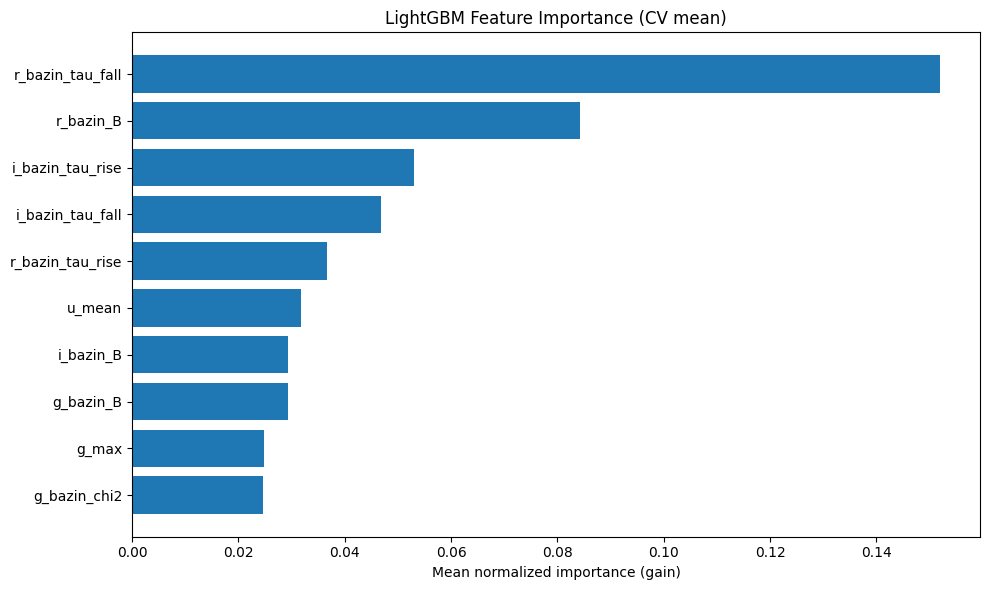

,feature,importance
64,r_bazin_tau_fall,0.151900
65,r_bazin_B,0.084324
69,i_bazin_tau_rise,0.053089
70,i_bazin_tau_fall,0.046820
63,r_bazin_tau_rise,0.036732
30,u_mean,0.031854
71,i_bazin_B,0.029368
59,g_bazin_B,0.029331
34,g_max,0.024786
60,g_bazin_chi2,0.024650


In [16]:
fi_df = get_cv_feature_importance(
    models=models,
    feature_names=X_train.columns,
    importance_type="gain"
)

fi_df.head(20)

In [20]:
def get_cv_feature_importance(
    models,
    feature_names,
    importance_type="gain",
    top_n=30,
    plot=True
):
    """
    Compute mean normalized feature importance over CV folds (LightGBM).

    Parameters
    ----------
    models : list
        List of fitted LightGBM models (one per CV fold)
    feature_names : list or pd.Index
        Feature names
    importance_type : str
        "gain" or "split"
    top_n : int
        Number of features to plot
    plot : bool
        Whether to plot importance

    Returns
    -------
    pd.DataFrame
        Feature importance dataframe
    """

    # Extraer importancias por fold
    importances = np.array([
        m.booster_.feature_importance(importance_type=importance_type)
        for m in models
    ])

    # Media entre folds
    mean_importance = importances.mean(axis=0)

    # Normalizar (suma = 1)
    mean_importance = mean_importance / mean_importance.sum()

    # DataFrame
    fi_df = pd.DataFrame({
        "feature": feature_names,
        "importance": mean_importance
    }).sort_values("importance", ascending=False)

    if plot:
        plt.figure(figsize=(12, max(6, top_n * 0.35)))
        sns.barplot(
            data=fi_df.head(top_n),
            x="importance",
            y="feature",
            palette="Set3",
            orient="h"
        )
        plt.xlabel(f"Mean normalized importance ({importance_type})")
        plt.ylabel("")
        plt.title("LightGBM Feature Importance (CV mean)")
        plt.tight_layout()
        plt.show()

    return fi_df

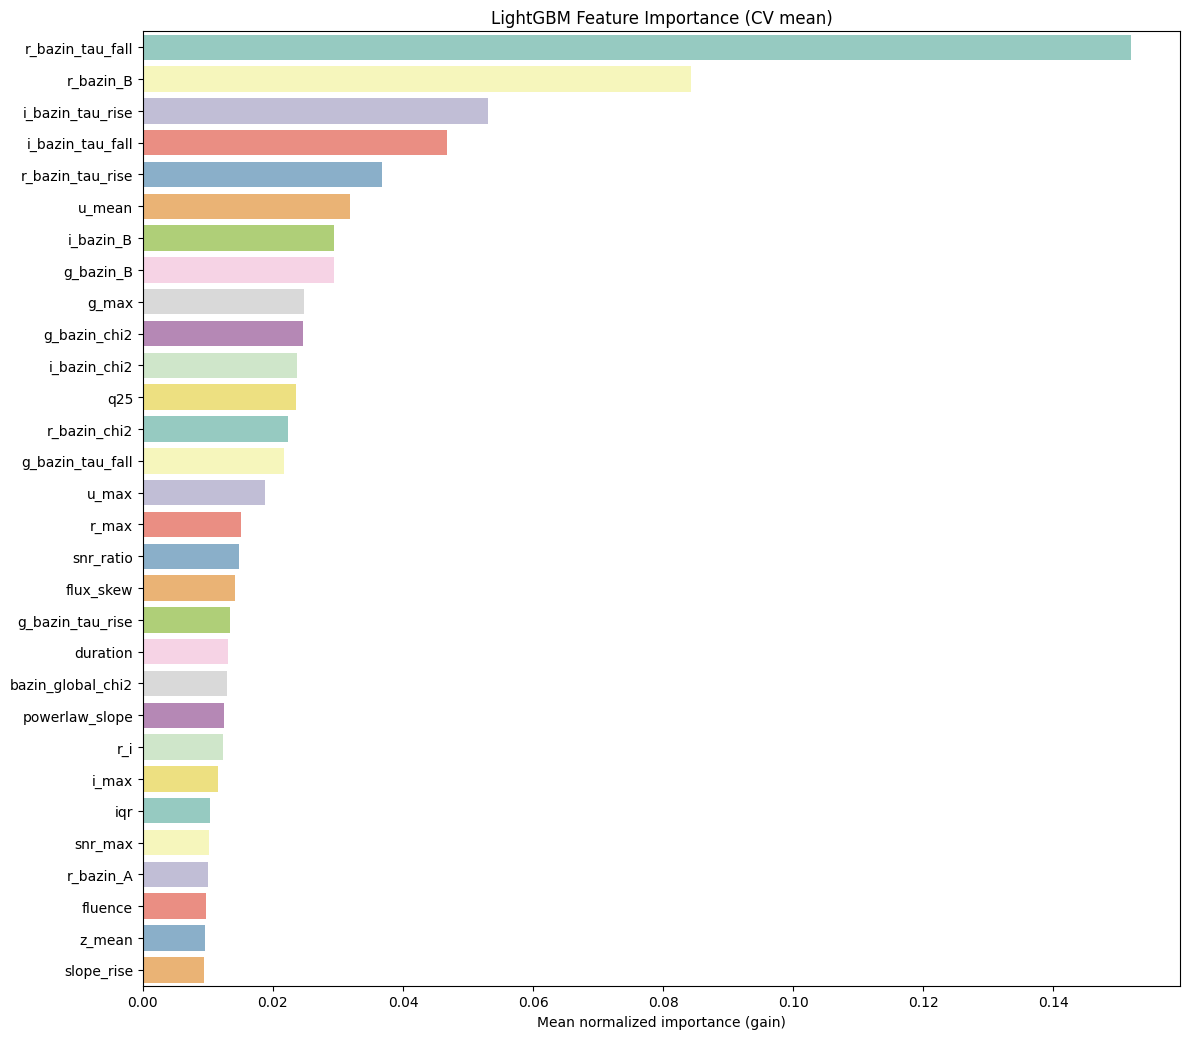

In [23]:
fi_gain = get_cv_feature_importance(models, X_train.columns, importance_type="gain")
# fi_split = get_cv_feature_importance(models, X_train.columns, importance_type="split")

## 6. Optimización threshold

In [19]:
# -------------------------------------------------
# 6️⃣ Optimización de threshold
# -------------------------------------------------
threshold = 0.05
oof_preds = (oof_probs > threshold).astype(int)

oof_f1 = f1_score(y, oof_preds)
oof_auc = roc_auc_score(y, oof_probs)

print("OOF F1:", oof_f1)
print("OOF AUC:", oof_auc)

OOF F1: 0.5460526315789473
OOF AUC: 0.9361247257620315


## 7. Submission

In [20]:
test_preds = (test_probs > best_th).astype(int)
submission = pd.DataFrame({
    "object_id": test_log["object_id"],
    "prediction": test_preds
})
submission.to_csv("submission_lgbm_tde_final_1.csv", index=False)